# Phase 2: Exploratory Data Analysis (EDA)

Phase 1 established that the training data is usable. This notebook investigates patterns and relationships in sales. It ends with dataset-derived EDA findings; feature engineering and model training belong to later phases.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PLOT_DIR = PROJECT_DIR / "plots" / "EDA plots"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
train_path = PROJECT_DIR / "data" / "train.csv"
df = pd.read_csv(train_path)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 9 columns):
 #   Column         Non-Null Count    Dtype
---  ------         --------------    -----
 0   Store          1017209 non-null  int64
 1   DayOfWeek      1017209 non-null  int64
 2   Date           1017209 non-null  str  
 3   Sales          1017209 non-null  int64
 4   Customers      1017209 non-null  int64
 5   Open           1017209 non-null  int64
 6   Promo          1017209 non-null  int64
 7   StateHoliday   1017209 non-null  str  
 8   SchoolHoliday  1017209 non-null  int64
dtypes: int64(7), str(2)
memory usage: 69.8 MB


## 1. Understand the Sales Target

Start with the target distribution and summary statistics. Use the histogram and descriptive statistics to assess skew and identify values worth investigating.

In [47]:
df.describe(include="all").T

count    1.017209e+06
mean     5.773819e+03
std      3.849926e+03
min      0.000000e+00
25%      3.727000e+03
50%      5.744000e+03
75%      7.856000e+03
max      4.155100e+04
Name: Sales, dtype: float64

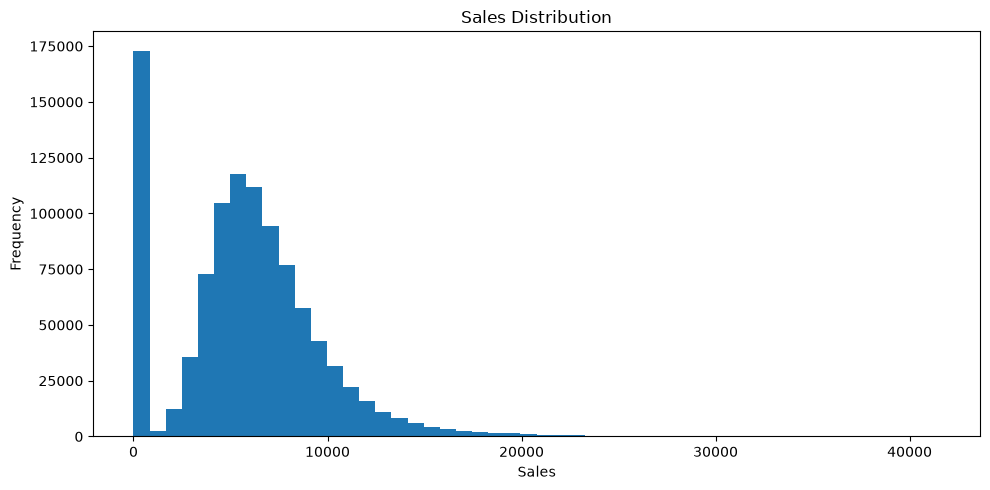

In [15]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.hist(df["Sales"], bins=50)
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.title("Sales Distribution")
plt.tight_layout()
plt.savefig(PLOT_DIR / "sales_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Sales Over Time

Aggregate sales by date to inspect trends, recurring patterns, and unusual spikes or drops.

In [16]:
df["Date"] = pd.to_datetime(df["Date"])

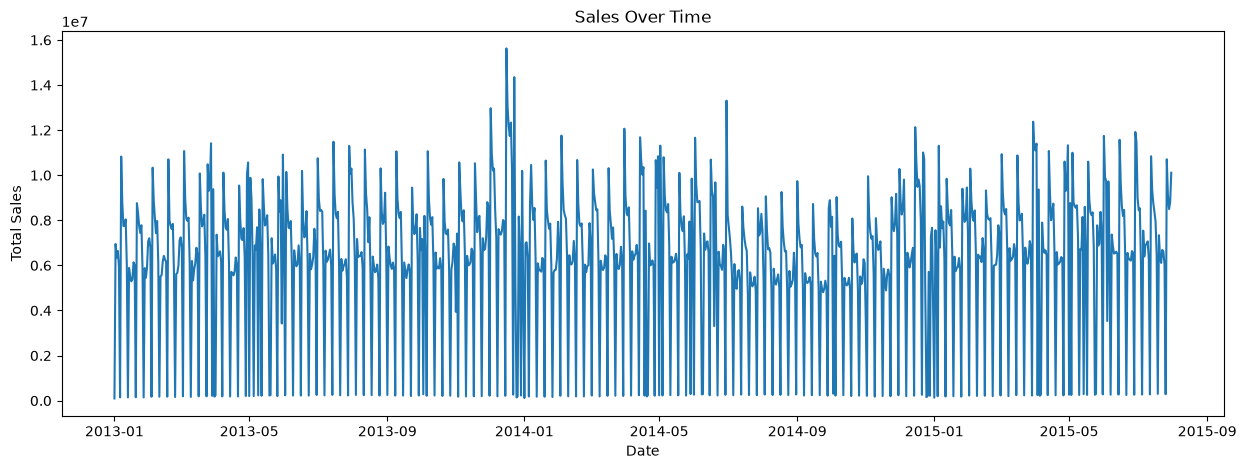

In [31]:
daily_sales = df.groupby("Date")["Sales"].sum()

plt.figure(figsize=(15,5))
plt.plot(daily_sales)
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Sales Over Time")
plt.savefig(PLOT_DIR / "daily_sales.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Sales by Day of Week

Compare average sales across weekdays to see whether some days are consistently stronger.

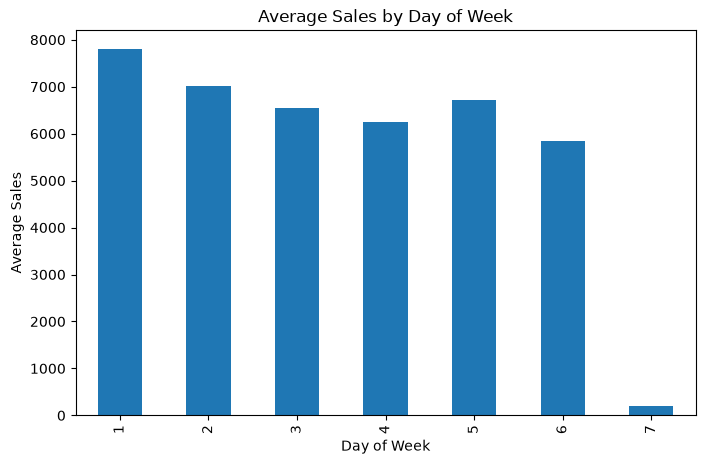

In [30]:
day_sales = df.groupby("DayOfWeek")["Sales"].mean()

day_sales.plot(kind="bar", figsize=(8,5))

plt.xlabel("Day of Week")
plt.ylabel("Average Sales")
plt.title("Average Sales by Day of Week")
plt.savefig(PLOT_DIR / "day_sales.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Promotion vs Sales

Compare mean sales on promotion and non-promotion days. This is an observed association, not evidence that promotion alone caused the difference.

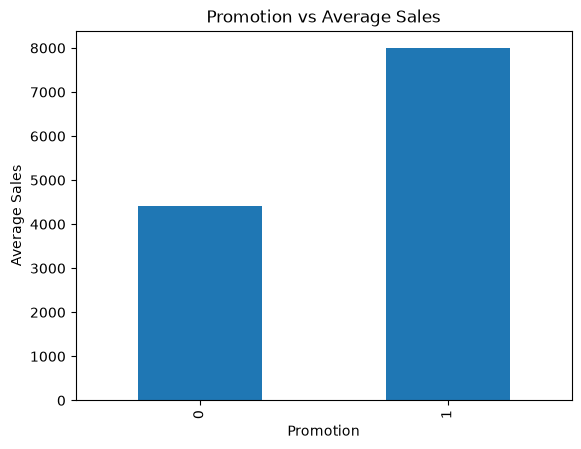

In [32]:
promo_sales = df.groupby("Promo")["Sales"].mean()

promo_sales.plot(kind="bar")

plt.xlabel("Promotion")
plt.ylabel("Average Sales")
plt.title("Promotion vs Average Sales")
plt.savefig(PLOT_DIR / "promo_sales.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Customers vs Sales

Inspect the relationship visually and with a correlation coefficient to assess whether customer count moves linearly with sales.

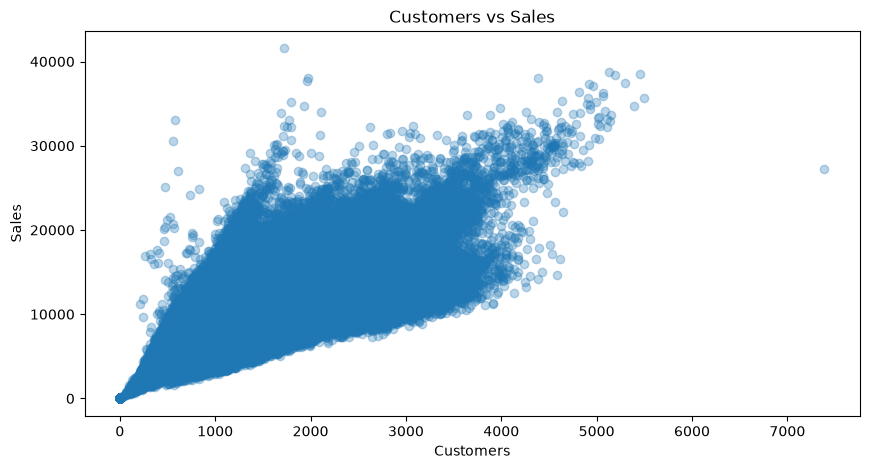

In [40]:
plt.figure(figsize=(10,5))

plt.scatter(
    df["Customers"],
    df["Sales"],
    alpha=0.3
)

plt.xlabel("Customers")
plt.ylabel("Sales")
plt.title("Customers vs Sales")
plt.savefig(PLOT_DIR / "customers_vs_sales.png", dpi=150, bbox_inches="tight")

plt.show()

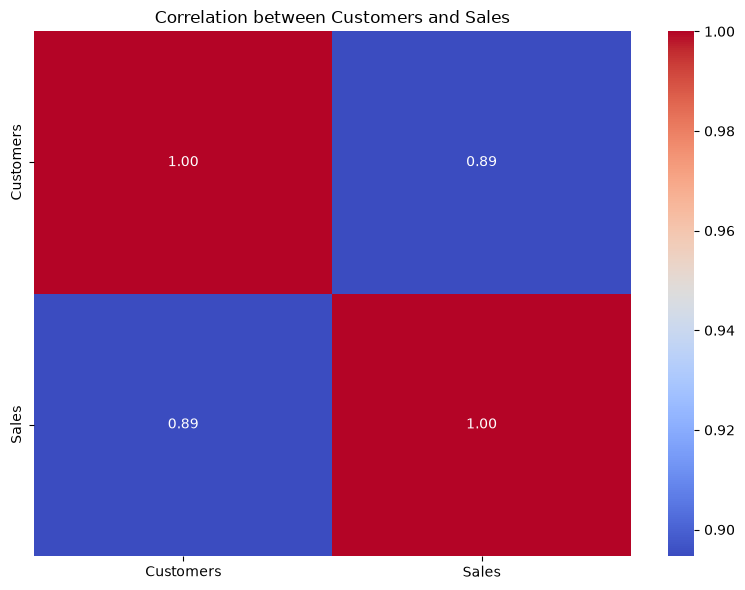

,Customers,Sales
Customers,1.000000,0.894711
Sales,0.894711,1.000000


In [51]:
customer_sales_corr = df[["Customers", "Sales"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(customer_sales_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation between Customers and Sales")
plt.tight_layout()
plt.savefig(PLOT_DIR / "customer_sales_correlation.png", dpi=150, bbox_inches="tight")
plt.show()

customer_sales_corr

## 6. Store Performance

Rank stores by average sales and inspect the full distribution across stores to understand how differently locations perform.

In [5]:
store_sales = (
    df.groupby("Store")["Sales"]
    .mean()
    .sort_values(ascending=False)
)

store_sales.head(10)

Store
262     20718.515924
817     18108.139066
562     17969.556263
1114    17200.196391
251     15814.087049
842     15242.114776
513     15129.942675
788     14949.194268
733     14933.288747
383     14320.466030
Name: Sales, dtype: float64

In [10]:
store_sales.tail(10)

Store
210    2641.309979
219    2591.467091
794    2553.475584
972    2550.559448
254    2485.839703
841    2461.395966
208    2443.791932
198    2407.933121
543    2313.468153
307    2244.503185
Name: Sales, dtype: float64

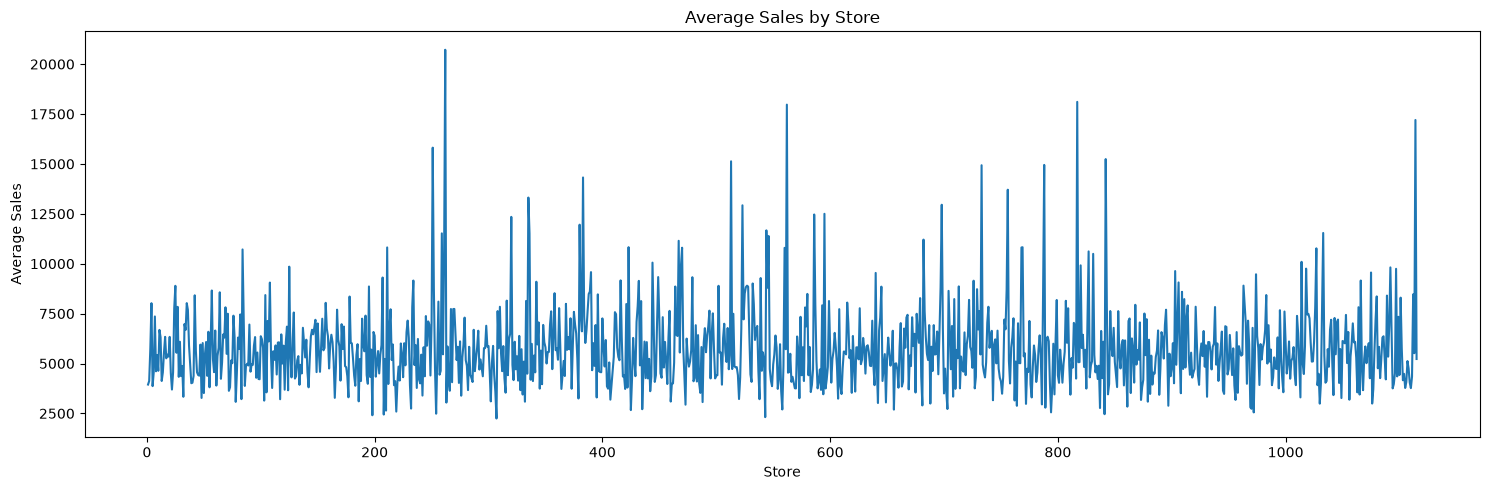

In [55]:
plt.figure(figsize=(15, 5))

store_sales.sort_index().plot()

plt.xlabel("Store")
plt.ylabel("Average Sales")
plt.title("Average Sales by Store")
plt.tight_layout()
plt.savefig(PLOT_DIR / "average_sales_by_store.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Monthly Sales

Group by calendar month to look for recurring seasonal patterns. The month value is used here only to summarize EDA results.

In [17]:
df["Month"] = df["Date"].dt.month

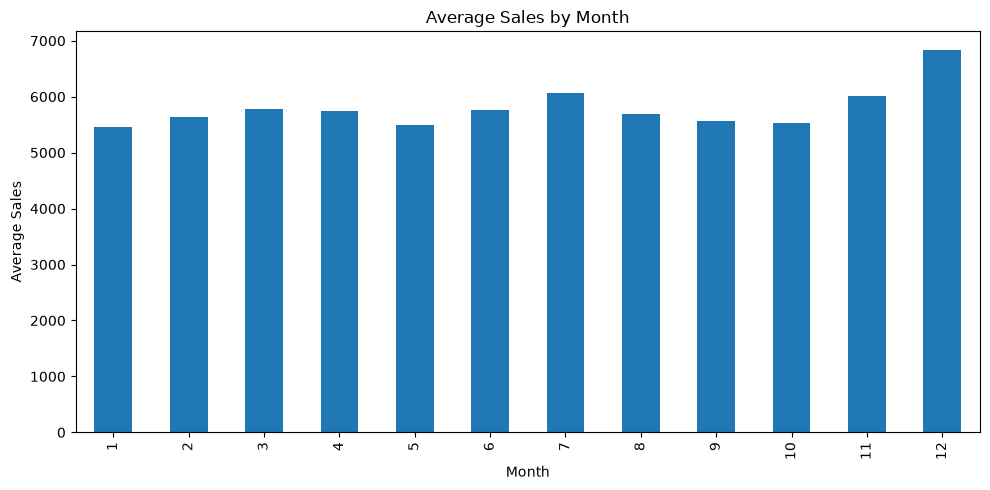

In [53]:
monthly_sales = df.groupby("Month")["Sales"].mean()
monthly_sales.plot(kind="bar", figsize=(10, 5))

plt.xlabel("Month")
plt.ylabel("Average Sales")
plt.title("Average Sales by Month")
plt.tight_layout()
plt.savefig(PLOT_DIR / "average_sales_by_month.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Yearly Sales

Compare mean sales by year to see whether overall sales levels change across the observed period.

In [25]:
df["Year"]=df["Date"].dt.year

yearly_sales=df.groupby("Year")["Sales"].mean()
print(yearly_sales.T)

Year
2013    5658.533675
2014    5833.290704
2015    5878.245380
Name: Sales, dtype: float64


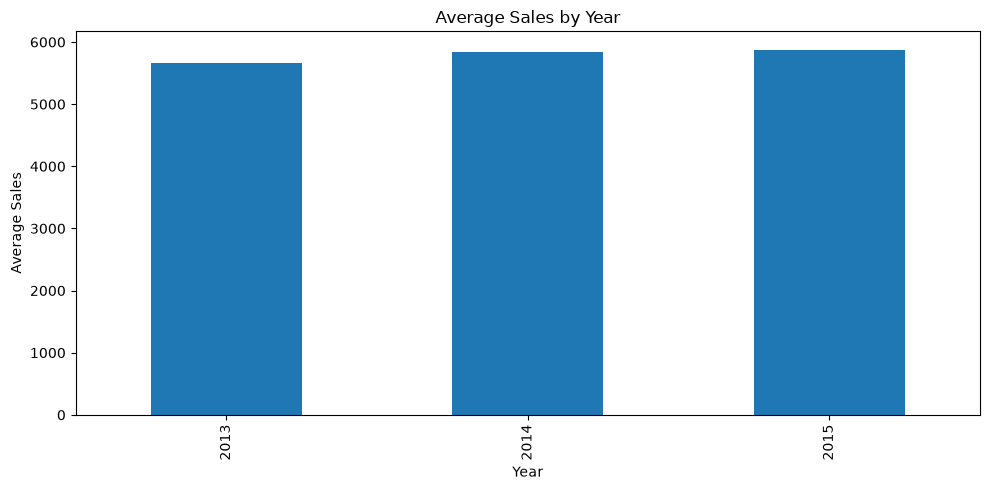

In [54]:
yearly_sales.plot(kind="bar", figsize=(10, 5))

plt.xlabel("Year")
plt.ylabel("Average Sales")
plt.title("Average Sales by Year")
plt.tight_layout()
plt.savefig(PLOT_DIR / "average_sales_by_year.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Holiday Effect

Compare mean sales for school and state holidays with their non-holiday groups. Interpret these as associations in this dataset.

In [39]:
School_holiday_sales = df.groupby("SchoolHoliday")["Sales"].mean()
print(School_holiday_sales.T)

SchoolHoliday
0    5620.979034
1    6476.522207
Name: Sales, dtype: float64


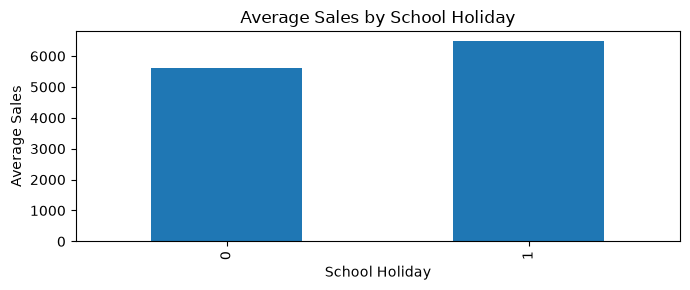

In [56]:
School_holiday_sales.plot(kind="bar", figsize=(7, 3))
plt.xlabel("School Holiday")
plt.ylabel("Average Sales")
plt.title("Average Sales by School Holiday")
plt.tight_layout()
plt.savefig(PLOT_DIR / "average_sales_by_school_holiday.png", dpi=150, bbox_inches="tight")
plt.show()

In [36]:
state_holiday_sales=df.groupby("StateHoliday")["Sales"].mean()
print(state_holiday_sales.T)

StateHoliday
0    5947.483893
a     290.735686
b     214.311510
c     168.733171
Name: Sales, dtype: float64


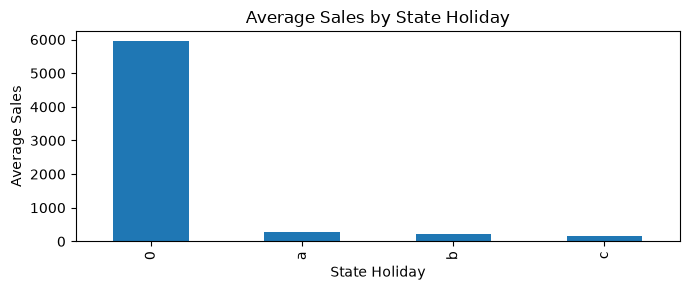

In [57]:
state_holiday_sales.plot(kind="bar", figsize=(7, 3))
plt.xlabel("State Holiday")
plt.ylabel("Average Sales")
plt.title("Average Sales by State Holiday")
plt.tight_layout()
plt.savefig(PLOT_DIR / "average_sales_by_state_holiday.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Correlation Analysis

Review correlations among numeric columns. Correlation describes linear association and does not establish causation; encoded category numbers may not have meaningful numeric distances.

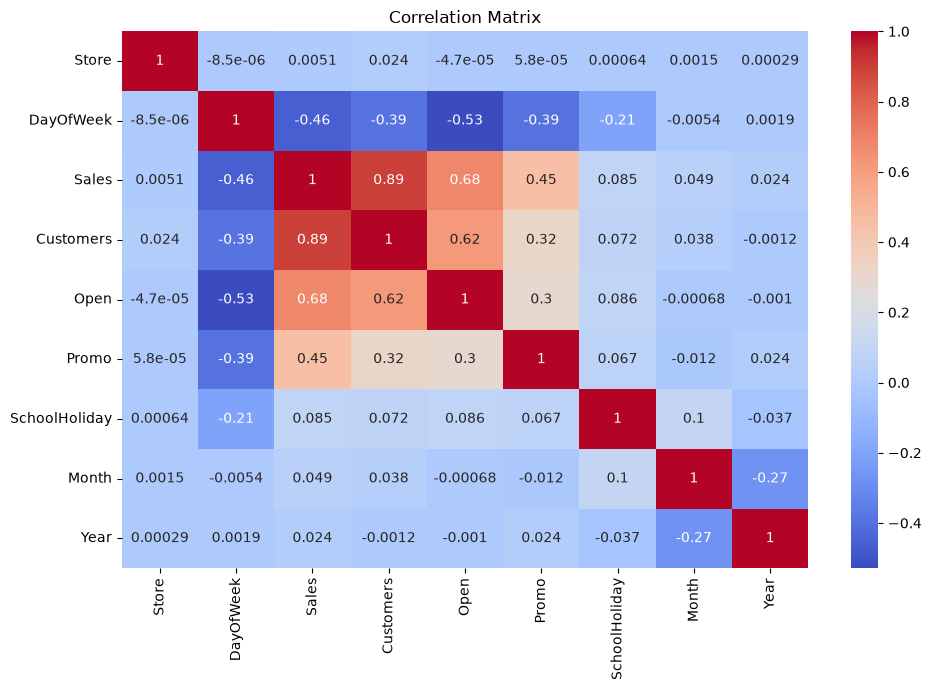

In [58]:
numeric_df = df.select_dtypes(include="number")
corr = numeric_df.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.savefig(PLOT_DIR / "correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## EDA Findings

The following findings are calculated from the loaded training data whenever this cell runs. Use them with the plots above; unusually high values are flagged for investigation, not automatically labeled as errors or outliers.

In [60]:
sales_skew = df["Sales"].skew()
sales_customer_corr = df[["Customers", "Sales"]].corr().loc["Customers", "Sales"]
store_means = df.groupby("Store")["Sales"].mean()
promo_means = df.groupby("Promo")["Sales"].mean()
day_means = df.groupby("DayOfWeek")["Sales"].mean()
month_means = df.groupby("Month")["Sales"].mean()
year_means = df.groupby("Year")["Sales"].mean()
school_holiday_means = df.groupby("SchoolHoliday")["Sales"].mean()
state_holiday_means = df.groupby("StateHoliday")["Sales"].mean()

skew_description = "right-skewed" if sales_skew > 0 else "left-skewed" if sales_skew < 0 else "approximately symmetric"
promo_change = (promo_means.loc[1] / promo_means.loc[0] - 1) * 100 if 0 in promo_means.index and 1 in promo_means.index and promo_means.loc[0] else None

print("EDA FINDINGS")
print(f"1. Sales are {skew_description} (skewness: {sales_skew:.2f}); mean: {df['Sales'].mean():,.2f}, median: {df['Sales'].median():,.2f}.")
print(f"   99th percentile: {df['Sales'].quantile(0.99):,.2f}; maximum: {df['Sales'].max():,.2f}. Investigate high values in context.")
print(f"2. Customers-Sales Pearson correlation: {sales_customer_corr:.3f}.")
print(f"3. Mean sales range across stores: {store_means.min():,.2f} to {store_means.max():,.2f}; highest store: {store_means.idxmax()}, lowest store: {store_means.idxmin()}.")
print(f"4. Mean sales by Promo: {promo_means.round(2).to_dict()}")
if promo_change is not None:
    print(f"   Mean sales difference for Promo=1 vs Promo=0: {promo_change:+.1f}%.")
print(f"5. Highest- and lowest-sales weekdays: {day_means.idxmax()} ({day_means.max():,.2f}) and {day_means.idxmin()} ({day_means.min():,.2f}).")
print(f"6. Highest- and lowest-sales months: {month_means.idxmax()} ({month_means.max():,.2f}) and {month_means.idxmin()} ({month_means.min():,.2f}).")
print(f"7. Mean sales by year: {year_means.round(2).to_dict()}")
print(f"8. Mean sales by SchoolHoliday: {school_holiday_means.round(2).to_dict()}")
print(f"9. Mean sales by StateHoliday: {state_holiday_means.round(2).to_dict()}")
print("10. Correlations are associations, not causal effects; review category encoding and store-level differences before drawing conclusions.")

EDA FINDINGS
1. Sales are right-skewed (skewness: 0.64); mean: 5,773.82, median: 5,744.00.
   99th percentile: 17,160.00; maximum: 41,551.00. Investigate high values in context.
2. Customers-Sales Pearson correlation: 0.895.
3. Mean sales range across stores: 2,244.50 to 20,718.52; highest store: 262, lowest store: 307.
4. Mean sales by Promo: {0: 4406.05, 1: 7991.15}
   Mean sales difference for Promo=1 vs Promo=0: +81.4%.
5. Highest- and lowest-sales weekdays: 1 (7,809.04) and 7 (204.18).
6. Highest- and lowest-sales months: 12 (6,826.61) and 1 (5,465.40).
7. Mean sales by year: {2013: 5658.53, 2014: 5833.29, 2015: 5878.25}
8. Mean sales by SchoolHoliday: {0: 5620.98, 1: 6476.52}
9. Mean sales by StateHoliday: {'0': 5947.48, 'a': 290.74, 'b': 214.31, 'c': 168.73}
10. Correlations are associations, not causal effects; review category encoding and store-level differences before drawing conclusions.
